<a href="https://colab.research.google.com/github/nabilah-afrin/Computer-vision-projects/blob/main/A%20Comprehensive%20Analysis%20of%20Training%20Dynamic%20Properties%20in%20Deep%20Neural%20Networks%20with%20CutMix%20Augmentation/Cutmix_Generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# General
import os
import numpy as np
import matplotlib.pyplot as plt
import random
# model
import tensorflow
import tensorflow as tf
import keras
from keras.models import Sequential
from tensorflow.keras.utils import Sequence
from keras.utils import to_categorical
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.preprocessing.image import ImageDataGenerator


In [ ]:
num_classes = 10
BATCH_SIZE = 128
IMG_SIZE = 32

In [ ]:
# The data, split between train and test sets:
(X_train, y_train), (X_test, y_test) = cifar10.load_data()
print('X_train shape:', X_train.shape)
print('y_test shape:', y_test.shape)
print(X_train.shape[0], 'train samples')
print(X_test.shape[0], 'test samples')

170498071/170498071 [==============================] - 13s 0us/step
X_train shape: (50000, 32, 32, 3)
y_test shape: (10000, 1)
50000 train samples
10000 test samples


In [ ]:
# Convert class vectors to binary class matrices.
y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')
X_train /= 255.
X_test /= 255.
steps = int(X_train.shape[0] / BATCH_SIZE)
steps_per_epoch = len(X_train) // BATCH_SIZE

In [ ]:
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
)

In [ ]:
class CutMixImageDataGenerator():
    def __init__(self, generator1, generator2, img_size, batch_size):
        self.batch_index = 0
        self.samples = generator1.n
        self.generator1 = generator1
        self.generator2 = generator2
        self.img_size = img_size
        self.batch_size = batch_size

    def reset_index(self):
        self.generator1._set_index_array()
        self.generator2._set_index_array()

    def reset(self):
        self.batch_index = 0
        self.generator1.reset()
        self.generator2.reset()
        self.reset_index()

    def get_steps_per_epoch(self):
        quotient, remainder = divmod(self.samples, self.batch_size)
        return (quotient + 1) if remainder else quotient

    def __len__(self):
        return self.get_steps_per_epoch()

    def __next__(self):
        if self.batch_index == 0:
            self.reset()

        crt_idx = self.batch_index * self.batch_size
        if crt_idx >= self.samples:
            self.batch_index = 0
            raise StopIteration

        reshape_size = self.batch_size
        last_step_start_idx = (self.get_steps_per_epoch() - 1) * self.batch_size
        if crt_idx == last_step_start_idx:
            reshape_size = self.samples - last_step_start_idx

        X_1, y_1 = self.generator1.__next__()
        X_2, y_2 = self.generator2.__next__()

        cut_ratio = np.random.beta(a=1, b=1, size=reshape_size)
        cut_ratio = np.clip(cut_ratio, 0.2, 0.8)
        label_ratio = cut_ratio.reshape(reshape_size, 1)
        cut_img = X_2

        X = X_1.copy()
        for i in range(reshape_size):
            cut_size = int((self.img_size - 1) * cut_ratio[i])
            y1 = tf.random.uniform(shape=[], minval=0, maxval=(self.img_size - 1) - cut_size, dtype=tf.int32).numpy()
            x1 = tf.random.uniform(shape=[], minval=0, maxval=(self.img_size - 1) - cut_size, dtype=tf.int32).numpy()
            y2 = y1 + cut_size
            x2 = x1 + cut_size
            cut_arr = cut_img[i][y1:y2, x1:x2]
            X[i][y1:y2, x1:x2] = cut_arr

        y = y_1 * (1 - (label_ratio ** 2)) + y_2 * (label_ratio ** 2)
        self.batch_index += 1
        return X, y

    def __iter__(self):
        return self

In [ ]:
train_generator1 = datagen.flow(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)
train_generator2 = datagen.flow(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)

train_generator = CutMixImageDataGenerator(
    generator1=train_generator1,
    generator2=train_generator2,
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

# def generator_wrapper(generator):
#     first_run = True
#     while True:
#         try:
#             X, y = next(generator)
#             if first_run:
#                 print(f'X shape: {X.shape}, y shape: {y.shape}')
#                 first_run = False
#             yield X, y
#         except StopIteration:
#             generator.reset()
def generator_wrapper(generator):
    first_run = True
    while True:
        try:
            X, y = next(generator)
            if first_run:
                print(f'X shape: {X.shape}, y shape: {y.shape}')
                first_run = False  # Set the flag to False after printing
            if X.shape[0] == BATCH_SIZE:
                yield X, y
            elif X.shape[0] < BATCH_SIZE:
                # Pad the batch if it is smaller than BATCH_SIZE
                X = np.pad(X, ((0, BATCH_SIZE - X.shape[0]), (0, 0), (0, 0), (0, 0)), 'constant')
                y = np.pad(y, ((0, BATCH_SIZE - y.shape[0]), (0, 0)), 'constant')
                yield X, y
        except StopIteration:
            generator.reset()

In [ ]:
train_dataset = tf.data.Dataset.from_generator(
    lambda: generator_wrapper(train_generator),
    output_signature=(
        tf.TensorSpec(shape=(BATCH_SIZE, IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32),
        tf.TensorSpec(shape=(BATCH_SIZE, 10), dtype=tf.float32),
    )
)

train_dataset = (train_dataset
            .shuffle(1024)
            .cache()
            .repeat()
            .prefetch(buffer_size=tf.data.experimental.AUTOTUNE))

X shape: (128, 32, 32, 3), y shape: (128, 10)
X_cutmix shape: (128, 32, 32, 3), y_cutmix shape: (128, 10)
Max pixel value: 1.0
Min pixel value: 0.0
Image 0 shape: (32, 32, 3), max: 0.9589568376541138, min: 0.013464829884469509
Image 1 shape: (32, 32, 3), max: 0.9971153140068054, min: 0.036496005952358246
Image 2 shape: (32, 32, 3), max: 0.9955942630767822, min: 0.07504655420780182
Image 3 shape: (32, 32, 3), max: 0.9999812245368958, min: 0.04205389320850372
Image 4 shape: (32, 32, 3), max: 0.9999365210533142, min: 0.020323285833001137
Image 5 shape: (32, 32, 3), max: 0.9080765247344971, min: 0.03631634637713432
Image 6 shape: (32, 32, 3), max: 0.901465117931366, min: 0.00040152494329959154
Image 7 shape: (32, 32, 3), max: 0.9463752508163452, min: 0.022355426102876663
Image 8 shape: (32, 32, 3), max: 0.9994995594024658, min: 0.0006058432627469301


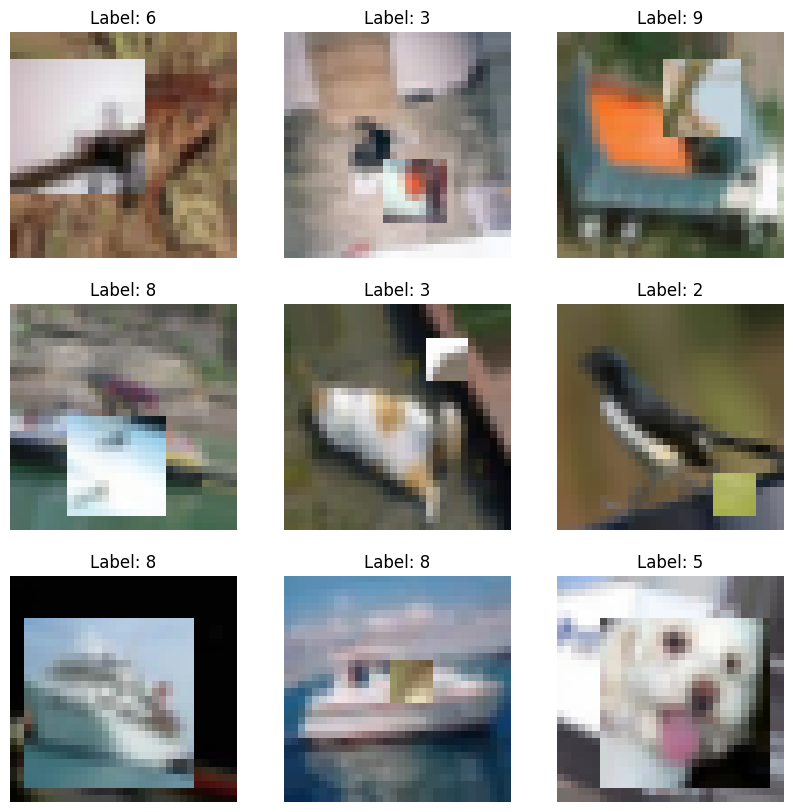

In [ ]:
# Function to plot images
def plot_images(images, labels, num_images=9):
    plt.figure(figsize=(10, 10))
    for i in range(num_images):
        plt.subplot(3, 3, i + 1)
        image = images[i]
        plt.imshow(image)
        plt.title(f'Label: {np.argmax(labels[i])}')
        plt.axis('off')
    plt.show()

# Generate one batch from the dataset
X_cutmix, y_cutmix = next(iter(train_dataset))

# Print shapes and ranges for verification
print(f"X_cutmix shape: {X_cutmix.shape}, y_cutmix shape: {y_cutmix.shape}")
print(f"Max pixel value: {X_cutmix.numpy().max()}")
print(f"Min pixel value: {X_cutmix.numpy().min()}")

# Check individual image shapes
for i in range(9):
    print(f"Image {i} shape: {X_cutmix[i].shape}, max: {X_cutmix[i].numpy().max()}, min: {X_cutmix[i].numpy().min()}")

# Plot images
plot_images(X_cutmix.numpy(), y_cutmix.numpy(), num_images=9)
